# What Should a Streaming Service Learn from a Popular-Movie Catalogue?
### A TMDB catalogue case study: genre performance, rating reliability and content discovery

*Simulated business case study using a public TMDB dataset. It is not analysis commissioned by any company, and the dataset contains no viewing, revenue or subscriber data.*

---

## Executive summary

Using 9,827 movies that were popular on TMDB around March 2022, this analysis asks how a streaming or entertainment company could use catalogue data to understand audience preferences and plan content discovery.

1. **The most common genres are not the best rated.** Drama (38% of movies), Comedy (31%), Action (27%) and Thriller (25%) dominate the catalogue. But among movies with at least 50 votes, Action, Comedy and Thriller all rate *below* the catalogue average of 6.56, and Horror is lowest at 6.04. The highest-rated genres are niche: Documentary (7.36), History, Music, War and Animation (about 7.0), each with a 95% confidence interval entirely above the average.
2. **Popularity, engagement and quality are different signals.** TMDB popularity is only weakly related to rating (Spearman 0.13) and moderately to vote count (0.40). Popularity is mainly a *recency* signal: the median 2021 release scores about 51, versus 20–24 for every release year from 2010 to 2020.
3. **Ratings from few votes are unreliable.** Rating spread is twice as wide for movies with under 10 votes (SD 1.65) as for movies with 1,000+ votes (SD 0.77). Of the 10 highest *raw* ratings, 7 have fewer than 350 votes. A vote-weighted rating moves them down to rank 500–2,300 and surfaces established titles instead.
4. **Non-English movies rate higher in every genre compared.** They make up 20% of rating-qualified movies but rate 0.14 to 0.62 points higher than English-language movies *within the same genre*. This is likely partly a selection effect, so it is a hypothesis to test, not proof of higher quality.
5. **A transparent shortlist finds 234 "hidden gems".** These are movies in the top 10% by vote-weighted rating but in the bottom half of current popularity, mostly older titles: candidates for discovery features such as collections and editorial picks.

**Recommendations** (Section 8): use vote-weighted ratings, not raw ratings or popularity, to rank movies in discovery surfaces; treat niche high-rated genres as curation opportunities rather than volume plays; pilot an international and "hidden gems" discovery row and measure it with an A/B test.

## 1. Business problem and objectives

**Scenario.** A streaming service wants to use catalogue metadata to make better discovery and catalogue-planning decisions: which genres audiences rate well, which signals to trust when ranking titles, and which well-liked titles are under-exposed.

**Objectives**

- Describe what the catalogue is made of (genre mix and overlap) without double counting movies.
- Compare genre rating performance in a way that accounts for sample size and rating uncertainty.
- Establish whether popularity, vote count and rating can be used interchangeably.
- Show how the genre mix in the dataset differs by release decade.
- Build a transparent, defensible shortlist method for content discovery.

**Out of scope.** Revenue, viewing hours, retention, subscriber behaviour and production budgets are not in the dataset, so no conclusion here is about commercial performance.

## 2. Dataset description and scope

**Source.** [9000+ Movies Dataset on Kaggle](https://www.kaggle.com/datasets/disham993/9000-movies-dataset), file `mymoviedb.csv`, collected from the TMDB API and sorted by popularity. The file has no collection date; the latest release date with any votes is 10 March 2022, so the snapshot was taken on or shortly after that date.

| Field | Meaning | Used for |
|---|---|---|
| `Release_Date` | Release date | Year, decade, recency |
| `Title` | Movie title | Identification, duplicate checks |
| `Overview` | Plot summary | Duplicate checks only |
| `Popularity` | TMDB's popularity score at snapshot time, driven by recent page views, votes and watchlist activity | Q3, Q5 |
| `Vote_Count` | Number of TMDB user ratings | Rating reliability, engagement proxy |
| `Vote_Average` | Average TMDB user rating, 0–10 | Rating analysis |
| `Original_Language` | ISO language code | International-content analysis |
| `Genre` | Comma-separated TMDB genres | Genre analysis |
| `Poster_Url` | Poster image link | Not used (no analytical value) |

**Scope.** This is a list of movies that were *popular on TMDB at one moment*, not a random sample of all films. Every finding describes this catalogue, not the film industry as a whole.

## 3. Business questions and analytical plan

| # | Question | Decision it could inform | Metric | Method | Main limitation |
|---|---|---|---|---|---|
| Q1 | Which genres make up the catalogue, and how much do they overlap? | Catalogue description, browse taxonomy | % of movies tagged with each genre | Counts on the movie-genre table, counting each movie once per genre | Genres are TMDB tags; most movies have several |
| Q2 | Which genres rate consistently better, after accounting for sample size? | Where to invest curation and acquisition attention | Mean and median rating, 95% CI, % in the top rating quartile | Rating-qualified movies (≥ 50 votes), t-based CIs | Movies in several genres make genre groups overlap; audience is TMDB users |
| Q3 | Are popularity, vote count and rating interchangeable? | Which signal should drive rankings | Pearson and Spearman correlation; median popularity by release year | Correlations on raw, log and rank scales; recency breakdown | Popularity is a snapshot score, not lifetime demand |
| Q4 | How does the genre mix change by release decade? | Context for catalogue gaps by era | % of each decade's movies in each genre | Decade shares with per-decade denominators | Reflects what is popular *today*, not historical production; 2020s incomplete |
| Q5 | Which movies are strong discovery candidates, and do international titles stand out? | Editorial rows, "hidden gems", international collections | Vote-weighted rating; popularity percentile; within-genre language gap | Bayesian-style shrinkage with a sensitivity check; stratified comparison | Shortlist is a ranking exercise, not a validated recommender |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Make the project's src/ package importable whether the notebook runs from notebooks/ or the repo root.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

from src import data_analysis as da
from src.data_analysis import PRIMARY, MUTED, ACCENT, INK

da.set_chart_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 60)

IMAGES_DIR = REPO_ROOT / "images"
IMAGES_DIR.mkdir(exist_ok=True)


def save(fig, name):
    """Save a chart to images/ so the README can show it."""
    fig.savefig(IMAGES_DIR / f"{name}.png")

## 4. Data quality audit

Before cleaning anything, every check is run on the raw file and the result is recorded. The raw data is never modified; cleaning produces separate tables in Section 5.

In [2]:
raw = da.load_raw()  # data/raw/mymoviedb.csv, or the MOVIE_DATA_PATH environment variable
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head(3)

9,827 rows × 9 columns


,Release_Date,Title,Overview,Popularity,Vote_Count,Vote_Average,Original_Language,Genre,Poster_Url
0,2021-12-15,Spider-Man: No Way Home,Peter Parker is unmasked and no longer able to separate ...,"5,083.95",8940,8.30,en,"Action, Adventure, Science Fiction",https://image.tmdb.org/t/p/original/1g0dhYtq4irTY1GPXvft...
1,2022-03-01,The Batman,"In his second year of fighting crime, Batman uncovers co...","3,827.66",1151,8.10,en,"Crime, Mystery, Thriller",https://image.tmdb.org/t/p/original/74xTEgt7R36Fpooo50r9...
2,2022-02-25,No Exit,Stranded at a rest stop in the mountains during a blizza...,"2,618.09",122,6.30,en,Thriller,https://image.tmdb.org/t/p/original/vDHsLnOWKlPGmWs0kGfu...


In [3]:
audit = da.quality_audit(raw)
audit

,check,rows,meaning
0,Rows,9827,Records in the raw file
1,Missing values (any column),0,Rows with at least one missing field
2,Fully duplicated rows,0,Identical in every column
3,Unparseable release dates,0,Dates that fail to parse
4,Release date after inferred snapshot,58,"Released after 2022-03-10, the latest release date that ..."
5,Vote count = 0,100,"No votes, so the 0.0 rating is a placeholder"
6,Vote count < 0,0,Impossible value
7,Vote average outside 0–10,0,Impossible value
8,Vote average = 0 with votes > 0,0,Would indicate a real zero rating
9,Vote count 1–49,931,"Rated, but on too few votes to compare reliably"


**What the audit shows**

- The file is structurally clean: no missing values, no impossible ratings, vote counts or popularity scores, no unparseable dates and no empty genres.
- **100 movies have zero votes.** Their `Vote_Average` of 0.0 is a placeholder meaning "not rated yet", not a terrible rating. No movie has a 0.0 rating *with* votes, which confirms this reading.
- **58 movies were released after the inferred snapshot date** (10 March 2022), the latest release date that has any votes. These are upcoming releases that were already trending.
- **931 more movies have between 1 and 49 votes**: rated, but on too few votes to compare reliably (examined in Section 6).
- **314 rows repeat an earlier title, but none repeat title + release date.** The next cell checks what these are.

In [4]:
zero_votes = raw[raw["Vote_Count"] == 0]
zero_vote_years = pd.to_datetime(zero_votes["Release_Date"]).dt.year
print(f"Zero-vote movies: {len(zero_votes)}")
print(f"  released 2022 or later: {(zero_vote_years >= 2022).sum()}")
print(f"  released before 2022:   {(zero_vote_years < 2022).sum()}")
zero_votes[["Title", "Release_Date", "Popularity", "Vote_Average"]].head(5)

Zero-vote movies: 100
  released 2022 or later: 91
  released before 2022:   9


,Title,Release_Date,Popularity,Vote_Average
80,Sonic the Hedgehog 2,2022-03-30,317.16,0.00
210,Fast & Furious 10,2023-04-06,181.22,0.00
231,Dragon Ball Super: Super Hero,2022-04-22,170.55,0.00
232,After Ever Happy,2022-08-25,169.96,0.00
314,The Bad Guys,2022-03-17,146.55,0.00


Most zero-vote movies (91 of 100) are 2022 or later releases that were trending before anyone could rate them. **Treatment:** they stay in the catalogue (they count for genre mix) but their rating is set to missing, so a placeholder 0.0 can never pull an average down.

In [5]:
repeat_titles = raw[raw["Title"].duplicated(keep=False)].sort_values(["Title", "Release_Date"])
print(f"Titles appearing more than once: {repeat_titles['Title'].nunique()} titles, {len(repeat_titles)} rows")
repeat_titles[["Title", "Release_Date", "Original_Language", "Vote_Count", "Vote_Average"]].head(8)

Titles appearing more than once: 288 titles, 602 rows


,Title,Release_Date,Original_Language,Vote_Count,Vote_Average
3270,365 Days,2015-05-22,te,12,4.80
1424,365 Days,2020-02-07,pl,6540,7.00
5993,A Christmas Carol,1984-10-09,en,241,7.30
2052,A Christmas Carol,2009-11-04,en,3732,6.90
1599,A Nightmare on Elm Street,1984-11-09,en,3877,7.30
2169,A Nightmare on Elm Street,2010-04-30,en,2187,5.50
5902,Adventures in Babysitting,1987-07-01,en,491,6.80
3703,Adventures in Babysitting,2016-06-24,en,316,7.40


The repeated titles are different films that share a name: remakes (*Aladdin* 1992 and 2019), unrelated films (*365 Days*, a 2015 Telugu film and a 2020 Polish one) and re-releases. Treating title alone as a duplicate key would wrongly delete 314 real movies.

**Why title + release date is the duplicate key, and its limits.** Two entries for the same film would normally share both. The key would miss a duplicate entered with a slightly different date or title spelling, and it would wrongly merge two different films released the same day under the same name. Neither case occurs here: no title + date pair repeats, and the one title + overview repeat is a remake with the same plot text. So **no rows are removed as duplicates.**

## 5. Cleaning and feature engineering

`da.clean_movies()` builds the movie-level table and logs the row count after every step. `da.explode_genres()` builds the movie-genre table. Both live in `src/data_analysis.py`, so every rule is defined once and covered by unit tests.

| Table | Grain | Use it for |
|---|---|---|
| `movies` | One row per movie | Counting movies, popularity, votes, years, shortlists |
| `movie_genres` | One row per movie per genre | Per-genre questions only. A movie with three genres appears three times, so this table must never be used to count movies |

**Engineered fields:** `release_year`, `decade`, `genre_list`, `n_genres`, `is_english`, `released_by_snapshot`, `has_votes`, `rating` (= `vote_average`, missing when there are no votes) and `rating_qualified` (at least 50 votes).

In [6]:
movies, cleaning_log = da.clean_movies(raw)
movie_genres = da.explode_genres(movies)
cleaning_log

,step,rows,note
0,Raw file,9827,
1,Drop unparseable release dates,9827,0 removed
2,Drop duplicate title + release date,9827,0 removed
3,"Movies with no votes (rating set to missing, kept in cat...",100,kept
4,Rating-qualified movies (>= 50 votes),8796,used for rating analysis


In [7]:
rated = movies[movies["rating_qualified"]]  # movie-level table for all rating analysis
print(f"movies:       {len(movies):,} rows, one per movie")
print(f"movie_genres: {len(movie_genres):,} rows across {movie_genres['genre'].nunique()} genres")
print(f"rated:        {len(rated):,} movies with >= {da.MIN_VOTES} votes ({len(rated) / len(movies):.0%} of movies)")

movies:       9,827 rows, one per movie
movie_genres: 25,793 rows across 19 genres
rated:        8,796 movies with >= 50 votes (90% of movies)


**Decisions and reasons**

- **Rows removed: 0.** Every raw record is either a valid movie or a not-yet-rated movie that still belongs in the catalogue.
- **Unused fields are kept, not deleted.** `Overview` was used for the duplicate check and `Poster_Url` has no analytical use; they stay in `movies` so the table remains a faithful copy of the source.
- **`Original_Language` is kept and used**, because international content is a real discovery question (Q5).
- **Genre values** are split on commas, trimmed and checked: no empty genres, no movie lists the same genre twice, and the genre table has exactly one row per genre tag (asserted inside `explode_genres`).

## 6. Exploratory data analysis

This section checks the shape of each metric before any comparison, because skewed or noisy metrics need different methods.

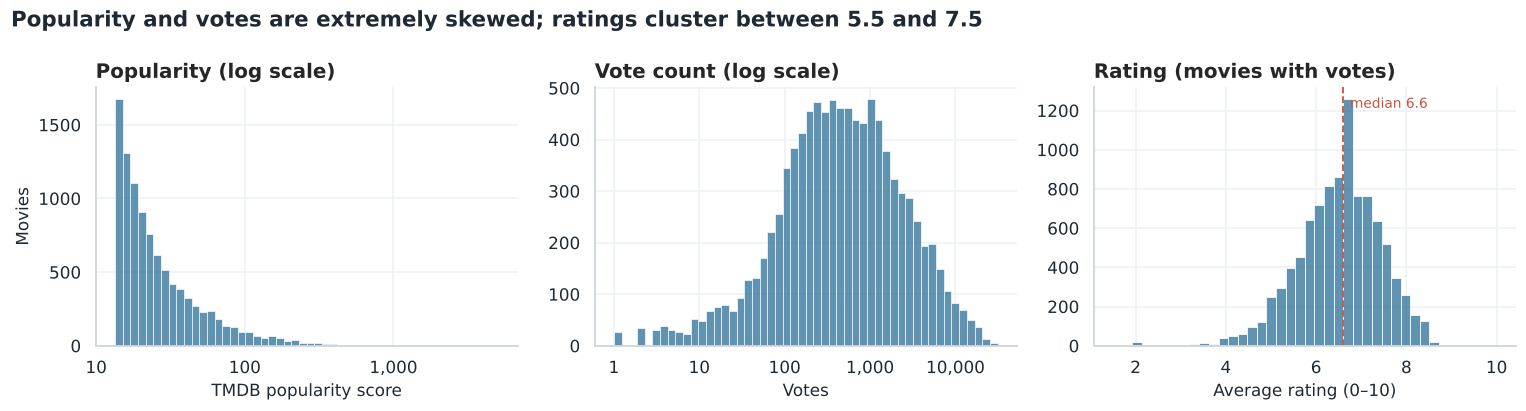

              count     mean      std   min    50%      90%       99%  \
popularity 9,827.00    40.33   108.87 13.35  21.20    66.21    282.20   
vote_count 9,827.00 1,392.81 2,611.21  0.00 444.00 3,647.00 13,870.04   
rating     9,727.00     6.51     0.93  1.50   6.50     7.60      8.40   

                 max  
popularity  5,083.95  
vote_count 31,077.00  
rating         10.00  
Skewness: popularity 21.9, vote count 4.1, rating -0.6


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

sns.histplot(movies["popularity"], bins=50, log_scale=True, color=PRIMARY, ax=axes[0])
axes[0].set(title="Popularity (log scale)", xlabel="TMDB popularity score", ylabel="Movies")

sns.histplot(movies.loc[movies["has_votes"], "vote_count"], bins=50, log_scale=True, color=PRIMARY, ax=axes[1])
axes[1].set(title="Vote count (log scale)", xlabel="Votes", ylabel="")

sns.histplot(movies["rating"].dropna(), bins=40, color=PRIMARY, ax=axes[2])
axes[2].axvline(rated["rating"].median(), color=ACCENT, linestyle="--", linewidth=1.2)
axes[2].text(rated["rating"].median() + 0.15, axes[2].get_ylim()[1] * 0.92,
             f"median {rated['rating'].median():.1f}", color=ACCENT, fontsize=9)
axes[2].set(title="Rating (movies with votes)", xlabel="Average rating (0–10)", ylabel="")

for ax in axes[:2]:
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Popularity and votes are extremely skewed; ratings cluster between 5.5 and 7.5",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "01_distributions")
plt.show()

print(movies[["popularity", "vote_count", "rating"]].describe(percentiles=[0.5, 0.9, 0.99]).T)
print(f"Skewness: popularity {movies['popularity'].skew():.1f}, vote count {movies['vote_count'].skew():.1f}, rating {movies['rating'].skew():.1f}")

**Interpretation**

- **Popularity** has a median of 21 but a maximum of 5,084 (skewness 21.9). The top 1% of movies hold 19% of all popularity points. The distribution also stops abruptly at 13.35: the file is the top slice of TMDB's popularity ranking, not the full database, which confirms that it is not a random sample of films. Means and raw Pearson correlations on this column would be dominated by a handful of blockbusters, so this analysis uses medians, log scales and rank correlations.
- **Vote count** is also heavily skewed: the median movie has 444 votes, the top 10% more than 3,600.
- **Ratings** are concentrated (most between 5.5 and 7.5) with a long left tail of poorly rated films. Differences of 0.3–0.5 points between groups are therefore meaningful in this data.
- **Outliers are genuine, not errors.** Spider-Man: No Way Home (popularity 5,084) was the biggest release of the snapshot period. They stay in the data; robust methods stop them from dominating.

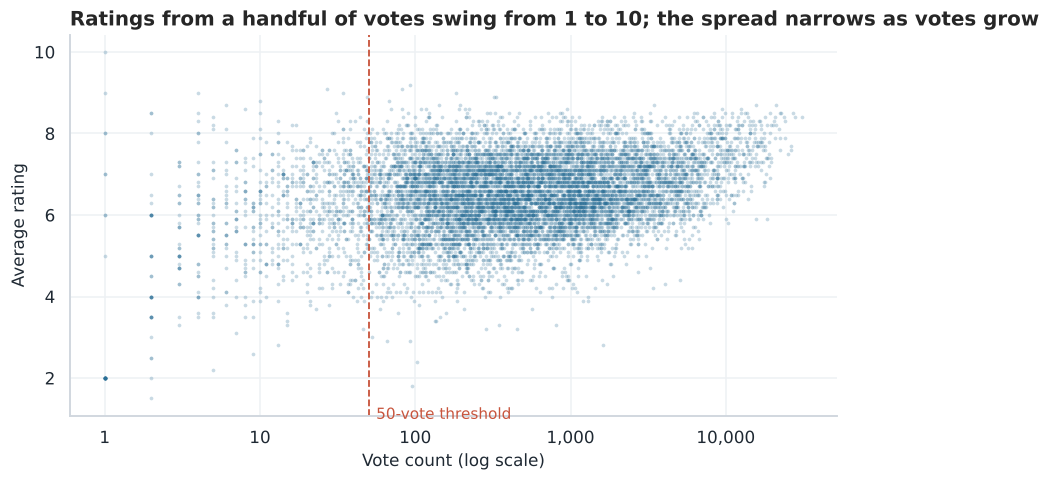

,movies,mean_rating,std_rating
vote_count,,,
1–9,260,5.46,1.65
10–49,671,6.21,1.04
50–199,2079,6.37,0.96
200–999,3559,6.46,0.83
"1,000+",3158,6.79,0.77


In [9]:
vote_buckets = pd.cut(movies["vote_count"], [0, 9, 49, 199, 999, np.inf],
                      labels=["1–9", "10–49", "50–199", "200–999", "1,000+"])
noise = (movies[movies["has_votes"]]
         .groupby(vote_buckets[movies["has_votes"]], observed=True)["rating"]
         .agg(movies="count", mean_rating="mean", std_rating="std"))

fig, ax = plt.subplots(figsize=(9, 4.5))
votes_present = movies[movies["has_votes"]]
ax.scatter(votes_present["vote_count"], votes_present["rating"], s=6, alpha=0.25, color=PRIMARY, linewidths=0)
ax.axvline(da.MIN_VOTES, color=ACCENT, linestyle="--", linewidth=1.2)
ax.text(da.MIN_VOTES * 1.12, 1.0, f"{da.MIN_VOTES}-vote threshold", color=ACCENT, fontsize=10)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set(title="Ratings from a handful of votes swing from 1 to 10; the spread narrows as votes grow",
       xlabel="Vote count (log scale)", ylabel="Average rating")
save(fig, "02_rating_noise")
plt.show()
noise

**Interpretation.** With fewer than 10 votes, ratings have a standard deviation of 1.65 and run from 1.5 to 10. With 1,000+ votes the spread halves (SD 0.77). Low-vote ratings mostly reflect a few individual opinions, not audience consensus.

**Decision:** all rating comparisons use movies with **at least 50 votes** (8,796 movies, 90% of the catalogue). Above 50 votes, the spread stabilises (SD 0.96 or lower). The threshold is a judgement call; the Q5 shortlist uses a continuous vote-weighting method instead of a hard cut-off, and tests its sensitivity.

**Caveat:** mean rating also *rises* with vote count (6.37 for 50–199 votes vs 6.79 for 1,000+), because well-liked films attract more voters. Vote count is partly an outcome of quality, not just a measure of precision.

In [10]:
coverage = (rated.groupby("decade")
                 .agg(movies=("movie_id", "size"), mean_rating=("rating", "mean"),
                      median_popularity=("popularity", "median"), median_votes=("vote_count", "median")))
print(f"Release years covered: {movies['release_year'].min()}–{movies['release_year'].max()}")
print(f"Movies released 2000 or later: {(movies['release_year'] >= 2000).mean():.0%}")
coverage

Release years covered: 1902–2024
Movies released 2000 or later: 76%


,movies,mean_rating,median_popularity,median_votes
decade,,,,
1900,1,8.00,18.36,"1,284.00"
1920,11,7.82,15.39,846.00
1930,32,7.41,16.71,520.50
1940,48,7.37,16.64,427.50
1950,101,7.40,16.50,456.00
1960,198,7.23,16.74,405.00
1970,245,6.94,17.57,499.00
1980,597,6.62,18.16,530.00
1990,1004,6.55,19.44,691.00


**Older vs newer movies.** The catalogue is dominated by recent releases: 76% came out in 2000 or later, and only 636 rating-qualified movies predate 1980. Older movies rate much higher (7.4 on average for the 1950s vs 6.4–6.5 for the 2000s and 2010s).

That is almost certainly **survivorship**, not proof that old films were better. A 1950s film is only "popular on TMDB in 2022" if it is a recognised classic, while recent films appear regardless of quality. Any comparison across eras must keep this in mind.

In [11]:
from collections import Counter
from itertools import combinations

print(f"Movies with more than one genre: {(movies['n_genres'] > 1).mean():.0%}")
print(f"Genres per movie: median {movies['n_genres'].median():.0f}, max {movies['n_genres'].max()}")

pair_counts = Counter()
for genres_of_movie in movies["genre_list"]:
    pair_counts.update(combinations(sorted(genres_of_movie), 2))
pd.DataFrame(pair_counts.most_common(8), columns=["genre_pair", "movies"])

Movies with more than one genre: 84%
Genres per movie: median 3, max 8


,genre_pair,movies
0,"(Action, Thriller)",944
1,"(Drama, Thriller)",923
2,"(Action, Adventure)",919
3,"(Drama, Romance)",902
4,"(Animation, Family)",827
5,"(Comedy, Family)",806
6,"(Horror, Thriller)",707
7,"(Comedy, Drama)",701


**Genre overlap.** 84% of movies carry more than one genre (median 3). The most common pairings are Action + Thriller, Drama + Thriller, Action + Adventure and Drama + Romance. This is why genre counts must be computed per movie: summing tag counts would count the typical movie almost three times.

## 7. Main analytical findings

### Q1. Which genres make up the catalogue?

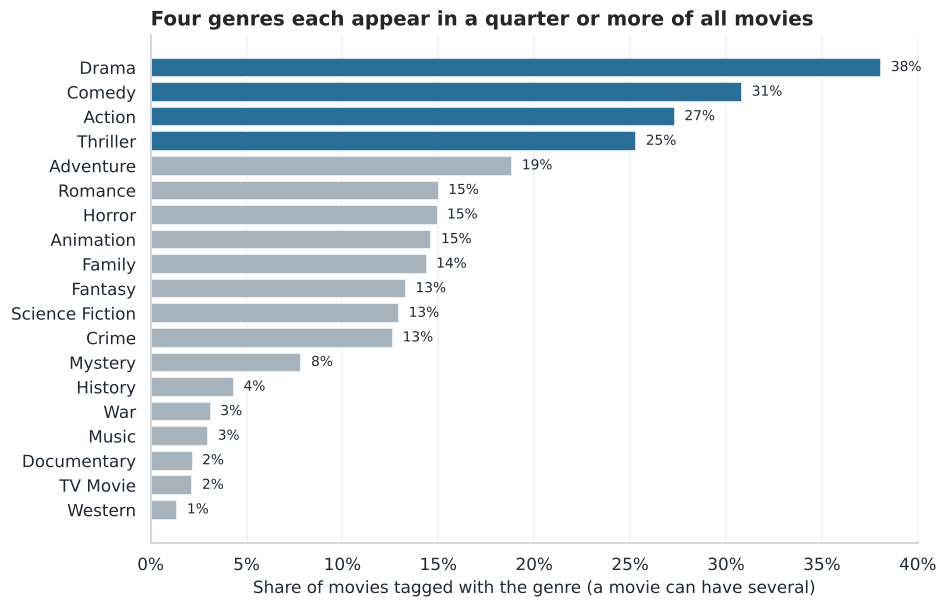

,movies,pct_of_movies
genre,,
Drama,3744,38.10
Comedy,3031,30.84
Action,2686,27.33
Thriller,2488,25.32
Adventure,1853,18.86
Romance,1476,15.02


In [12]:
prevalence = da.genre_prevalence(movies, movie_genres)

fig, ax = plt.subplots(figsize=(9, 6))
order = prevalence.index.astype(str)
colors = [PRIMARY if g in order[:4] else MUTED for g in order]
ax.barh(order, prevalence["pct_of_movies"], color=colors)
ax.invert_yaxis()
for y, pct in enumerate(prevalence["pct_of_movies"]):
    ax.text(pct + 0.5, y, f"{pct:.0f}%", va="center", fontsize=9, color=INK)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set(title="Four genres each appear in a quarter or more of all movies",
       xlabel="Share of movies tagged with the genre (a movie can have several)", ylabel="")
ax.grid(axis="y", visible=False)
save(fig, "03_genre_prevalence")
plt.show()
prevalence.head(6)

**What it shows.** Drama is tagged on 38% of movies, followed by Comedy (31%), Action (27%) and Thriller (25%). Documentary, TV Movie and Western each appear on 2% or less.

**Why it matters.** This describes *supply*: what the popular catalogue is made of. It says nothing about whether audiences rate those genres well; Q2 tests that separately.

**Caveat.** Shares sum to 262% because the average movie carries 2.6 genres. "Drama" is also a broad tag applied alongside many other genres.

### Q2. Which genres rate consistently better, after accounting for sample size?

Rating-qualified movies only (≥ 50 votes). "Top quartile" means a rating at or above 7.2, the 75th percentile of all qualified movies, so a genre that rates like everything else would have about 25% of its movies there.

In [13]:
top_quartile_cutoff = rated["rating"].quantile(0.75)
overall_mean = rated["rating"].mean()
genre_stats = da.genre_rating_summary(movie_genres, top_quartile_cutoff)
genre_stats = genre_stats.join(prevalence["pct_of_movies"])

print(f"Overall mean rating: {overall_mean:.2f}   top-quartile cutoff: {top_quartile_cutoff:.1f}")
genre_stats

Overall mean rating: 6.56   top-quartile cutoff: 7.2


,movies,mean_rating,ci_low,ci_high,median_rating,pct_top_quartile,pct_of_movies
genre,,,,,,,
Documentary,121,7.36,7.21,7.51,7.50,65.29,2.19
History,406,7.02,6.95,7.08,7.00,42.12,4.35
Music,273,7.01,6.92,7.10,7.00,40.66,3.00
War,287,6.99,6.91,7.08,7.00,42.86,3.13
Animation,1223,6.97,6.93,7.01,7.00,40.23,14.64
Drama,3401,6.83,6.80,6.85,6.90,36.90,38.10
Western,133,6.79,6.64,6.93,6.90,36.09,1.39
Romance,1315,6.69,6.65,6.74,6.70,29.66,15.02
Family,1331,6.64,6.60,6.69,6.70,25.85,14.39


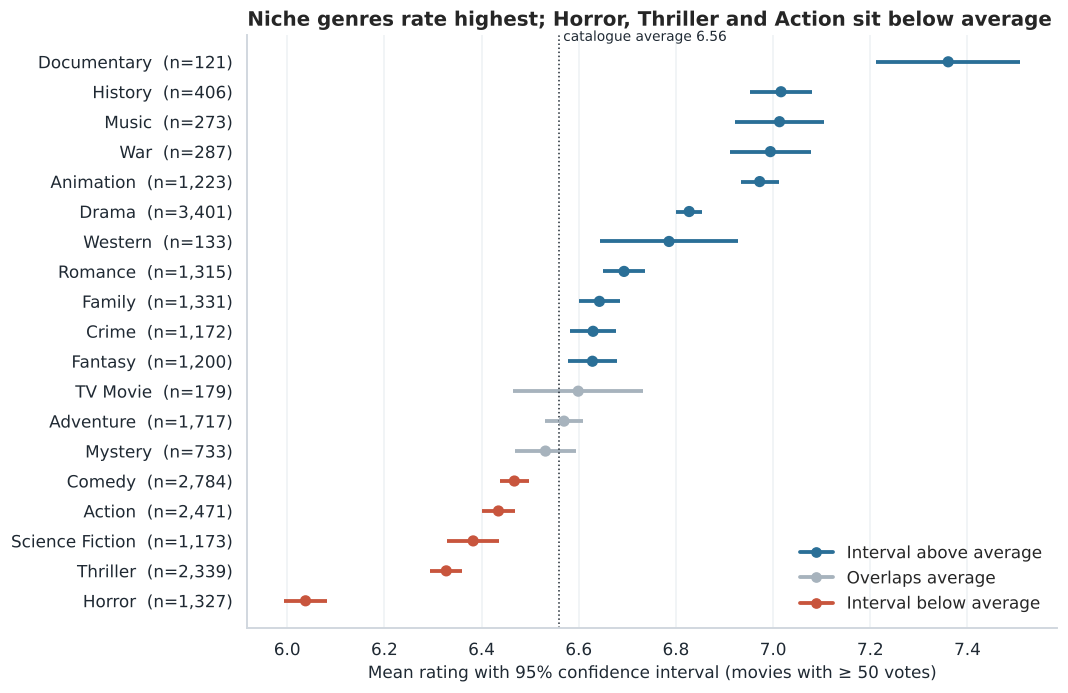

In [14]:
plot_df = genre_stats.sort_values("mean_rating")
position = np.arange(len(plot_df))
above = plot_df["ci_low"] > overall_mean
below = plot_df["ci_high"] < overall_mean
colors = np.where(above, PRIMARY, np.where(below, ACCENT, MUTED))

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.hlines(position, plot_df["ci_low"], plot_df["ci_high"], color=colors, linewidth=2.5)
ax.scatter(plot_df["mean_rating"], position, color=colors, s=40, zorder=3)
ax.axvline(overall_mean, color=INK, linestyle=":", linewidth=1)
ax.text(overall_mean, len(plot_df) - 0.3, f" catalogue average {overall_mean:.2f}", fontsize=9, color=INK)
ax.set_yticks(position, [f"{g}  (n={n:,})" for g, n in zip(plot_df.index.astype(str), plot_df["movies"])])
ax.set(title="Niche genres rate highest; Horror, Thriller and Action sit below average",
       xlabel="Mean rating with 95% confidence interval (movies with ≥ 50 votes)", ylabel="")
ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
legend_items = [Line2D([0], [0], color=c, marker="o", linewidth=2.5, label=l) for c, l in
                [(PRIMARY, "Interval above average"), (MUTED, "Overlaps average"), (ACCENT, "Interval below average")]]
ax.legend(handles=legend_items, loc="lower right")
save(fig, "04_genre_ratings_ci")
plt.show()

**What it shows.** Documentary is the clear leader (mean 7.36; 65% of its movies are in the top rating quartile). History, Music, War and Animation follow at about 7.0. At the bottom, Horror averages 6.04 with only 9% of its movies in the top quartile, and Thriller, Science Fiction, Action and Comedy are all below average. Of the four largest genres, only Drama (6.83) rates above average.

**Sample size and uncertainty.** Every confidence interval is narrow (at most ±0.15 points), because even the smallest genre has more than 100 qualified movies. Of the 19 genres, 11 have an interval entirely above the average and 5 entirely below it; only TV Movie, Adventure and Mystery overlap it. Some "above average" genres are only just above: Fantasy and Crime sit 0.07 points over the average, a difference no viewer would notice. The ranking within each group is less certain: History, Music and War are statistically indistinguishable from each other.

**Why it matters.** Genre is a useful prior for curation: high-rated genres are safer picks for "critically loved" collections, while for low-rated genres individual title quality matters more.

**Caveats.**
- The intervals treat this catalogue as if it were a sample of similar popular movies. It is not a random sample of all films, and movies in several genres appear in several groups, so groups are not independent.
- Ratings come from self-selected TMDB users. Documentaries, for instance, are mostly rated by people who chose to watch a documentary, which may inflate their scores relative to broad-audience genres.

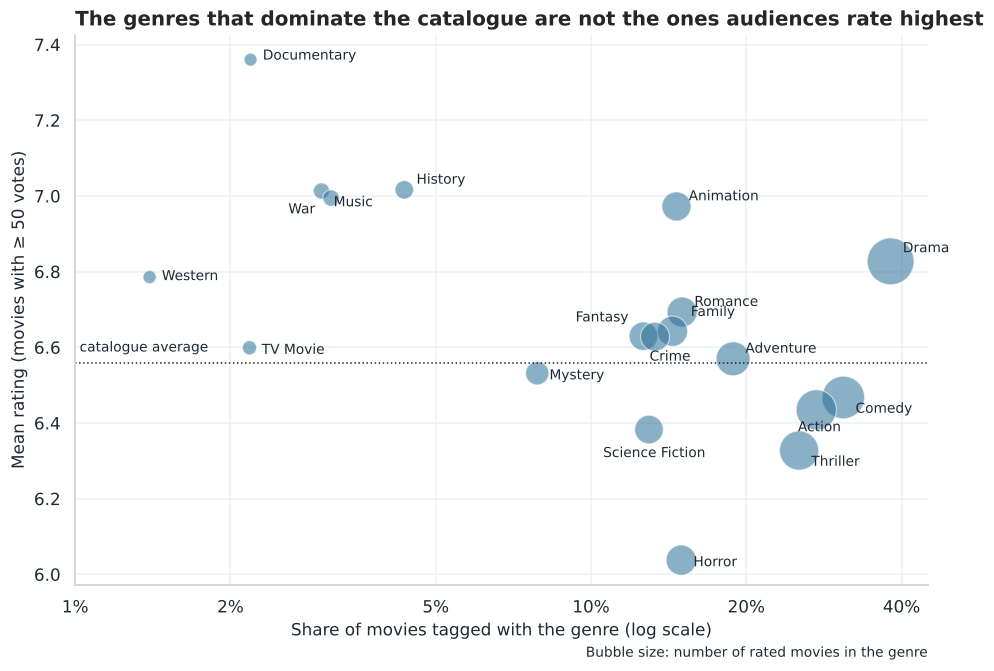

In [15]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sizes = genre_stats["movies"] / genre_stats["movies"].max() * 900 + 40
ax.scatter(genre_stats["pct_of_movies"], genre_stats["mean_rating"], s=sizes,
           color=PRIMARY, alpha=0.55, edgecolor="white", linewidth=0.8)
ax.axhline(overall_mean, color=INK, linestyle=":", linewidth=1)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}%"))
ax.set_xticks([1, 2, 5, 10, 20, 40])

label_offsets = {  # small manual nudges so labels don't collide
    "Drama": (8, 6), "Comedy": (8, -10), "Action": (-12, -14), "Thriller": (8, -10),
    "Adventure": (8, 4), "Romance": (8, 4), "Horror": (8, -4), "Animation": (8, 4),
    "Family": (12, 10), "Fantasy": (-52, 10), "Science Fiction": (-30, -18), "Crime": (4, -16),
    "Mystery": (8, -4), "History": (8, 4), "War": (-28, -10), "Music": (8, -10),
    "Documentary": (8, 0), "TV Movie": (8, -4), "Western": (8, -2),
}
for genre, row in genre_stats.iterrows():
    dx, dy = label_offsets.get(str(genre), (8, 0))
    ax.annotate(str(genre), (row["pct_of_movies"], row["mean_rating"]), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=INK)
ax.text(1.02, overall_mean + 0.03, "catalogue average", fontsize=9, color=INK)
ax.text(1.0, -0.13, "Bubble size: number of rated movies in the genre", transform=ax.transAxes,
        ha="right", fontsize=9, color=INK)
ax.set(title="The genres that dominate the catalogue are not the ones audiences rate highest",
       xlabel="Share of movies tagged with the genre (log scale)",
       ylabel="Mean rating (movies with ≥ 50 votes)")
save(fig, "05_prevalence_vs_rating")
plt.show()

**What it shows.** There is no positive link between how common a genre is and how well it rates. The four biggest genres (Drama, Comedy, Action, Thriller) split across both sides of the average, and the highest-rated genres (Documentary, History, Music, War) each make up 4% of the catalogue or less.

**Why it matters.** Volume and audience approval are separate dimensions. Genre prevalence describes the catalogue; rating describes reception. Using one as a proxy for the other would mislead catalogue planning.

**Caveat.** Bubble size shows the number of rated movies; the y-values come from the confidence-interval chart above.

### Q3. Are popularity, engagement and rating interchangeable?

Three different signals: **popularity** (TMDB's current-attention score), **vote count** (cumulative engagement) and **rating** (audience approval). If they were interchangeable, they would be strongly correlated.

In [16]:
correlations = da.correlation_table(rated, ["popularity", "vote_count", "rating"],
                                    log_columns=("popularity", "vote_count"))
correlations

,pearson_raw,pearson_log,spearman,n
pair,,,,
popularity vs vote_count,0.15,0.37,0.40,8796
popularity vs rating,0.08,0.16,0.13,8796
vote_count vs rating,0.28,0.25,0.22,8796


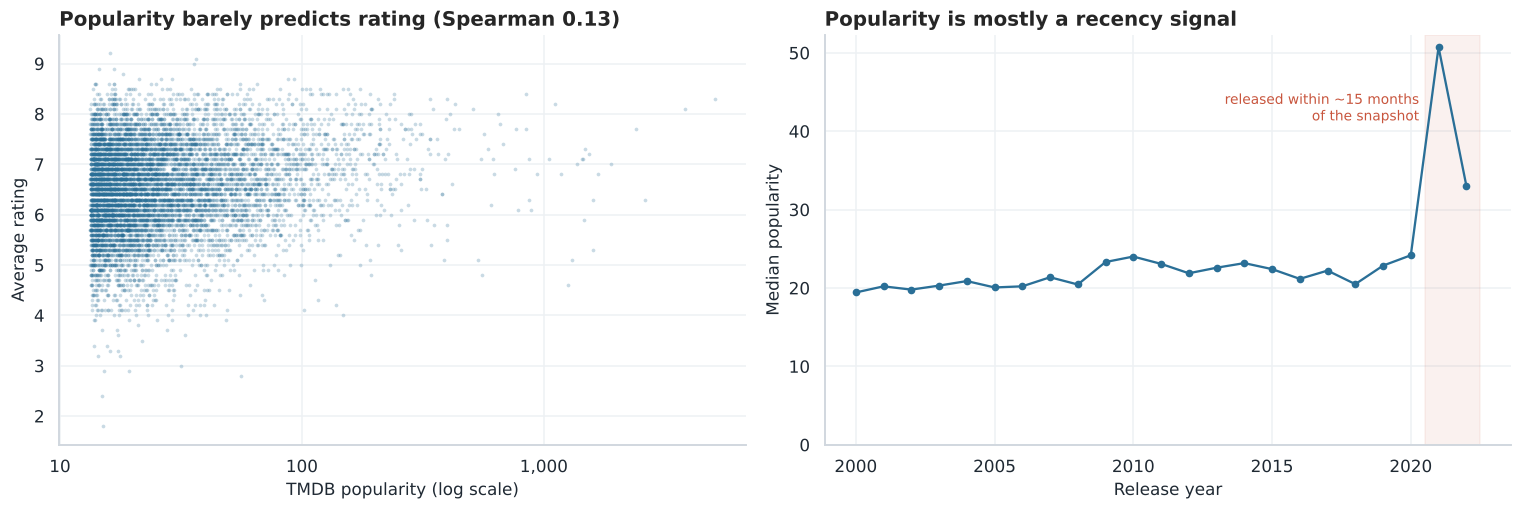

{2015: 22.4, 2016: 21.2, 2017: 22.2, 2018: 20.5, 2019: 22.9, 2020: 24.2, 2021: 50.7, 2022: 33.1}
2022 covers January to early March only.


In [17]:
# 2023-24 are excluded from the line: only 9 announced titles, too few for a stable median.
median_popularity_by_year = (movies[movies["release_year"].between(2000, 2022)]
                             .groupby("release_year")["popularity"].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].scatter(rated["popularity"], rated["rating"], s=6, alpha=0.25, color=PRIMARY, linewidths=0)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
rho = correlations.loc["popularity vs rating", "spearman"]
axes[0].set(title=f"Popularity barely predicts rating (Spearman {rho:.2f})",
            xlabel="TMDB popularity (log scale)", ylabel="Average rating")

axes[1].plot(median_popularity_by_year.index, median_popularity_by_year.values, color=PRIMARY, marker="o", markersize=4)
axes[1].axvspan(2020.5, 2022.5, color=ACCENT, alpha=0.08)
axes[1].text(2020.3, 45, "released within ~15 months\nof the snapshot", fontsize=9, color=ACCENT, ha="right", va="top")
axes[1].set(title="Popularity is mostly a recency signal", xlabel="Release year",
            ylabel="Median popularity", ylim=(0, None))

fig.tight_layout()
save(fig, "06_popularity_recency")
plt.show()

print(median_popularity_by_year.loc[2015:].round(1).to_dict())
print("2022 covers January to early March only.")

**What it shows.**

- **Popularity vs rating:** Spearman 0.13. Highly rated films are only marginally more popular, so popularity cannot stand in for quality.
- **Popularity vs vote count:** Spearman 0.40, the strongest of the three links, but still moderate. Both partly measure attention.
- **Vote count vs rating:** Spearman 0.22. Better-rated films collect somewhat more votes.
- **Extreme values matter.** For popularity vs vote count, raw Pearson is 0.15 but rises to 0.37 on a log scale. The raw figure is distorted by a few extreme movies, which is why rank-based (Spearman) correlation is the headline measure.
- **Recency:** median popularity is 20–24 for every release year from 2010 to 2020, then jumps to about 51 for 2021 releases. TMDB popularity measures *current attention*, which concentrates on new releases.

**Why it matters.** A discovery surface ranked by popularity will mostly show new releases; one ranked by raw rating will be distorted by low-vote outliers. These are different products ("trending now" vs "highly rated"), and each needs its own metric.

**Caveat.** These are associations in a snapshot. They do not show that popularity *causes* votes or that ratings *cause* attention.

### Q4. How does the genre mix change across release decades?

Share of each decade's movies tagged with each of the six most common genres, from the 1970s onward (earlier decades have fewer than 210 movies each). The denominator is the number of movies released in that decade, so shares are comparable across decades.

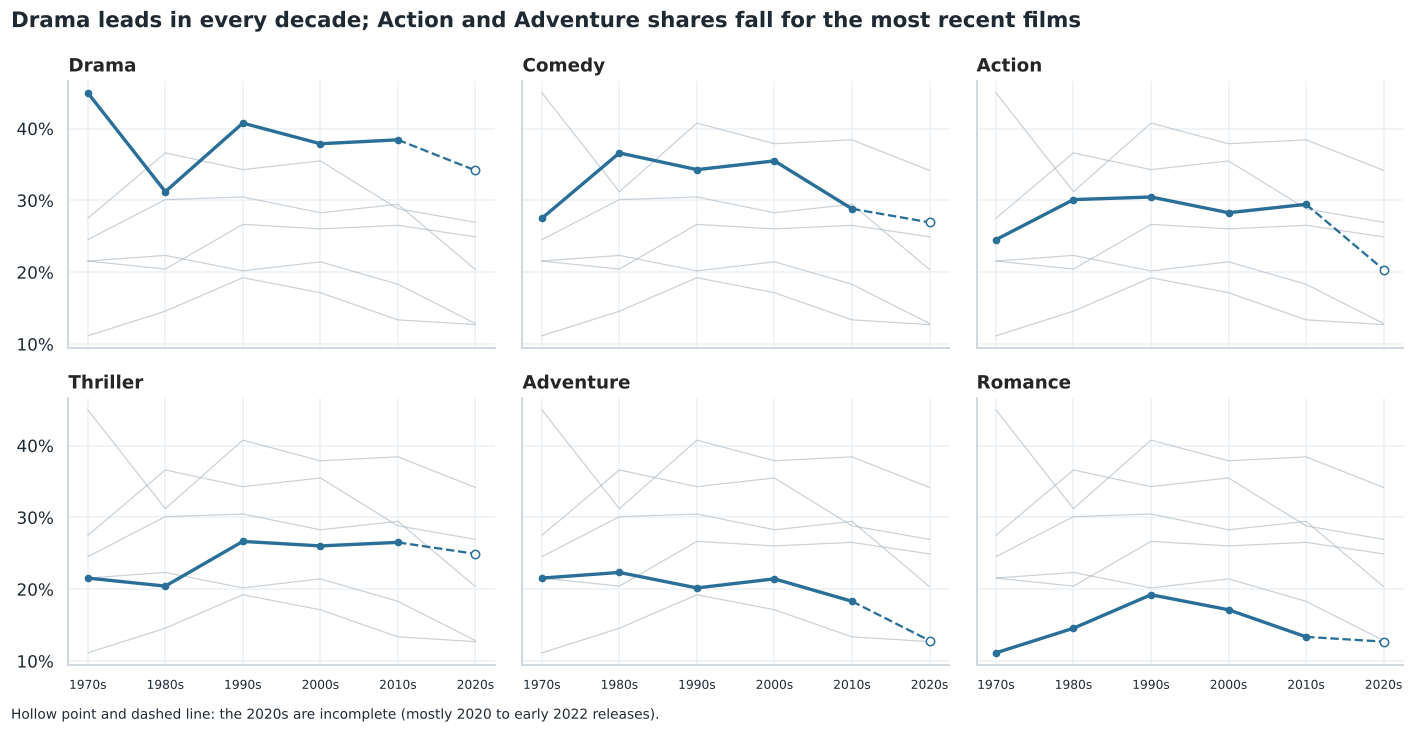

genre,movies_in_decade,Drama,Comedy,Action,Thriller,Adventure,Romance
decade,,,,,,,
1970,269,44.98,27.51,24.54,21.56,21.56,11.15
1980,631,31.22,36.61,30.11,20.44,22.35,14.58
1990,1050,40.76,34.29,30.48,26.67,20.19,19.24
2000,2093,37.89,35.50,28.28,26.04,21.45,17.15
2010,3999,38.43,28.83,29.46,26.53,18.33,13.38
2020,1384,34.18,26.95,20.38,24.93,12.86,12.72


In [18]:
top_genres = list(prevalence.index[:6].astype(str))
decade_mix = da.decade_genre_share(movies, movie_genres, top_genres, start_decade=1970)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey=True)
decades = decade_mix.index.to_numpy()
for ax, genre in zip(axes.flat, top_genres):
    for other in top_genres:
        if other != genre:
            ax.plot(decades, decade_mix[other], color=MUTED, linewidth=0.8, alpha=0.6)
    complete = decades < 2020
    ax.plot(decades[complete], decade_mix[genre][complete], color=PRIMARY, linewidth=2.2, marker="o", markersize=4)
    ax.plot(decades[-2:], decade_mix[genre].iloc[-2:], color=PRIMARY, linewidth=1.5, linestyle="--")
    ax.scatter(decades[-1], decade_mix[genre].iloc[-1], facecolor="white", edgecolor=PRIMARY, zorder=3, s=30)
    ax.set_title(genre, fontsize=12)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    ax.set_xticks(decades, [f"{d}s" for d in decades], fontsize=8)
fig.suptitle("Drama leads in every decade; Action and Adventure shares fall for the most recent films",
             x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK)
fig.text(0.01, -0.01, "Hollow point and dashed line: the 2020s are incomplete (mostly 2020 to early 2022 releases).",
         fontsize=9, color=INK)
fig.tight_layout()
save(fig, "07_genre_mix_by_decade")
plt.show()
decade_mix

**What it shows.** Drama stays the most common genre in every decade (31–45%). Comedy peaks for 1980s–2000s films (34–37%) and falls to 29% for 2010s films. Action is steady near 28–31% from the 1980s to the 2010s, then drops to 20% for 2020–22 releases; Adventure falls from 22% to 13% over the same span.

**Why it matters.** It shows which kinds of older films remain popular today: the older part of the catalogue leans toward Drama and Comedy classics, while recent popularity spreads across more genres.

**Caveats.**
- This is the genre mix **of movies popular on TMDB in 2022**, not of all films produced in each decade. It must not be read as a history of film production.
- The 2020s cover just over two years, including pandemic-era releases, when big-budget Action and Adventure films were delayed. That decade's values may change substantially.
- The 1970s has only 269 movies, so its shares move more from a few titles.

### Q5. Which movies are strong discovery candidates?

Raw ratings reward movies that a few people loved. A **vote-weighted rating** (the same idea as IMDb's published weighted-rating formula) shrinks each movie's rating toward the catalogue average in proportion to how few votes it has:

$$\text{weighted rating} = \frac{v}{v+m}\,R + \frac{m}{v+m}\,C$$

- $R$ = the movie's average rating, $v$ = its vote count
- $C$ = the mean rating of all rating-qualified movies (6.56)
- $m$ = the prior weight: the movie is treated as if it had $m$ extra votes at the average. Here $m$ = **555**, the median vote count of qualified movies, so a movie with a typical number of votes is pulled halfway toward the average.

The choice of $m$ is an assumption, not a fact. The sensitivity check below repeats the ranking with $m$ at the 75th percentile.

In [19]:
prior_mean = rated["rating"].mean()
prior_votes = rated["vote_count"].median()
strict_prior_votes = rated["vote_count"].quantile(0.75)

shortlist_base = rated.assign(
    weighted=da.weighted_rating(rated["rating"], rated["vote_count"], prior_votes, prior_mean),
    weighted_strict=da.weighted_rating(rated["rating"], rated["vote_count"], strict_prior_votes, prior_mean),
)
shortlist_base["raw_rank"] = shortlist_base["rating"].rank(ascending=False, method="min").astype(int)
shortlist_base["weighted_rank"] = shortlist_base["weighted"].rank(ascending=False, method="min").astype(int)

print(f"C (prior mean) = {prior_mean:.2f}, m (prior votes) = {prior_votes:.0f}; strict m = {strict_prior_votes:.0f}")
for k in (15, 50):
    base = set(shortlist_base.nlargest(k, "weighted")["movie_id"])
    strict = set(shortlist_base.nlargest(k, "weighted_strict")["movie_id"])
    print(f"Top {k}: {len(base & strict)} of {k} movies are the same under both priors")

print("\nThe 10 highest raw ratings, and where the weighted rating puts them:")
shortlist_base.nsmallest(10, "raw_rank")[["title", "vote_count", "rating", "raw_rank", "weighted_rank"]]

C (prior mean) = 6.56, m (prior votes) = 555; strict m = 1576
Top 15: 11 of 15 movies are the same under both priors
Top 50: 42 of 50 movies are the same under both priors

The 10 highest raw ratings, and where the weighted rating puts them:


,title,vote_count,rating,raw_rank,weighted_rank
7339,Franco Escamilla: Por La Anécdota,92,9.20,1,1719
2325,Impossible Things,82,9.10,2,1902
2391,The Three Deaths of Marisela Escobedo,183,9.00,3,1016
7041,Bring the Soul: The Movie,323,8.90,4,531
8648,Burn the Stage: The Movie,332,8.90,4,503
6198,Scooby-Doo! Adventures: The Mystery Map,68,8.80,6,2326
609,The Godfather,15614,8.70,7,2
657,The Shawshank Redemption,20911,8.70,7,1
3146,Dilwale Dulhania Le Jayenge,3474,8.70,7,13
3653,Violet Evergarden: The Movie,195,8.70,7,1148


**Why weighting matters.** Seven of the ten highest raw ratings belong to movies with fewer than 350 votes, such as a stand-up special (9.2 from 92 votes) and two concert films (8.9 from about 330 votes each). The weighted rating moves them to ranks between roughly 500 and 2,300, while long-established favourites (*The Godfather*, *The Shawshank Redemption*) move to the top.

**Sensitivity.** Under the stricter prior, 11 of the top 15 and 42 of the top 50 are unchanged. The shortlist is stable in substance, but the exact order depends on $m$, so it should be presented as a ranked candidate list, not an objective "best movies" list.

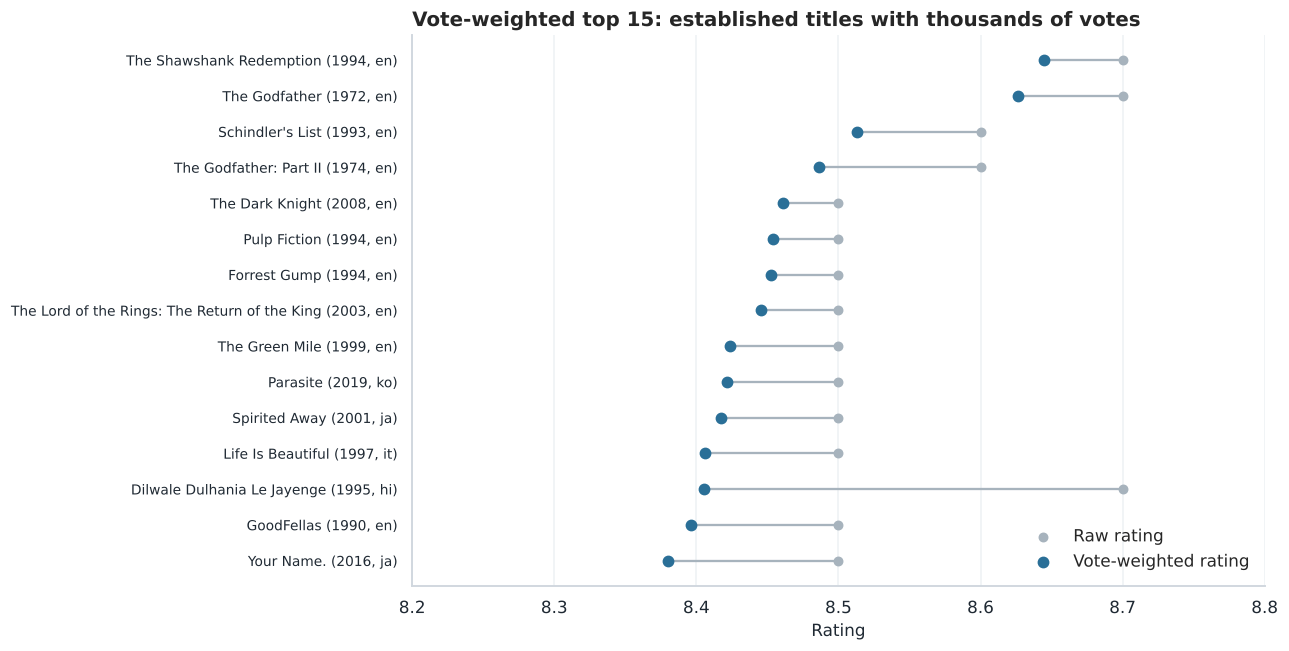

In [20]:
top15 = shortlist_base.nlargest(15, "weighted").iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(top15))
ax.hlines(y, top15["weighted"], top15["rating"], color=MUTED, linewidth=1.5)
ax.scatter(top15["rating"], y, color=MUTED, s=30, label="Raw rating", zorder=3)
ax.scatter(top15["weighted"], y, color=PRIMARY, s=45, label="Vote-weighted rating", zorder=3)
labels = [f"{t} ({yr}, {lang})" for t, yr, lang in zip(top15["title"], top15["release_year"], top15["original_language"])]
ax.set_yticks(y, labels, fontsize=9)
ax.set_xlim(8.2, 8.8)
ax.set(title="Vote-weighted top 15: established titles with thousands of votes",
       xlabel="Rating", ylabel="")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "08_weighted_top15")
plt.show()

**What it shows.** The vote-weighted top 15 are all movies with at least 3,400 votes; the weighting barely moves them because their ratings are well supported. Five of the 15 are non-English: Korean, Italian, Hindi and two Japanese titles.

**Why it matters.** A ranking that only surfaces movies like these is reliable but predictable: these titles need no help being discovered. The next step looks for movies that rate as well but get far less attention.

In [21]:
weighted_cutoff = shortlist_base["weighted"].quantile(0.90)
popularity_median = shortlist_base["popularity"].median()

hidden_gems = (shortlist_base[(shortlist_base["weighted"] >= weighted_cutoff) &
                              (shortlist_base["popularity"] <= popularity_median)]
               .sort_values("weighted", ascending=False))

print(f"Hidden gems: weighted rating >= {weighted_cutoff:.2f} (top 10%) and popularity <= {popularity_median:.1f} (bottom half)")
print(f"{len(hidden_gems)} movies; {(~hidden_gems['is_english']).mean():.0%} non-English; "
      f"{(hidden_gems['release_year'] < 2000).mean():.0%} released before 2000")
hidden_gems[["title", "release_year", "original_language", "genre", "vote_count", "rating", "weighted", "popularity"]].head(12)

Hidden gems: weighted rating >= 7.22 (top 10%) and popularity <= 21.3 (bottom half)
234 movies; 32% non-English; 54% released before 2000


,title,release_year,original_language,genre,vote_count,rating,weighted,popularity
8556,The Silence of the Lambs,1991,en,"Crime, Drama, Thriller",13012,8.30,8.23,14.58
5444,Cinema Paradiso,1988,it,"Drama, Romance",3259,8.50,8.22,19.72
7179,"Lock, Stock and Two Smoking Barrels",1998,en,"Comedy, Crime",5300,8.20,8.04,16.42
6980,Modern Times,1936,en,"Comedy, Drama",2866,8.30,8.02,16.74
4900,Room,2015,en,"Drama, Thriller",7865,8.10,8.00,21.23
6910,Sunset Boulevard,1950,en,Drama,1895,8.40,7.98,16.84
5987,Mommy,2014,fr,Drama,2241,8.30,7.95,18.56
7238,Paths of Glory,1957,en,"Drama, War",2124,8.30,7.94,16.34
6867,City Lights,1931,en,"Comedy, Drama, Romance",1584,8.40,7.92,16.90
8674,Requiem for a Dream,2000,en,"Crime, Drama",7920,8.00,7.91,14.45


**What it shows.** 234 movies are in the top 10% by weighted rating but in the bottom half by current popularity. They are mostly older, well-reviewed titles: *The Silence of the Lambs*, *Cinema Paradiso*, *Modern Times*, *Sunset Boulevard*, *Bicycle Thieves*. 32% are non-English and 54% were released before 2000.

**Why it matters.** These are natural candidates for discovery features such as "acclaimed classics" rows or editorial collections, because audiences rate them highly but they get little current attention.

**Caveat.** "High rating, low popularity" identifies candidates; it does not prove people would watch them. Low current attention might reflect limited availability, age or niche appeal. Only a live test can tell whether surfacing them increases viewing.

#### International titles

Non-English movies make up 20% of rating-qualified movies and average 6.96, against 6.46 for English-language movies. Part of that gap could be genre mix (for example, a high share of animation among Japanese films). The fair comparison is **within each genre**:

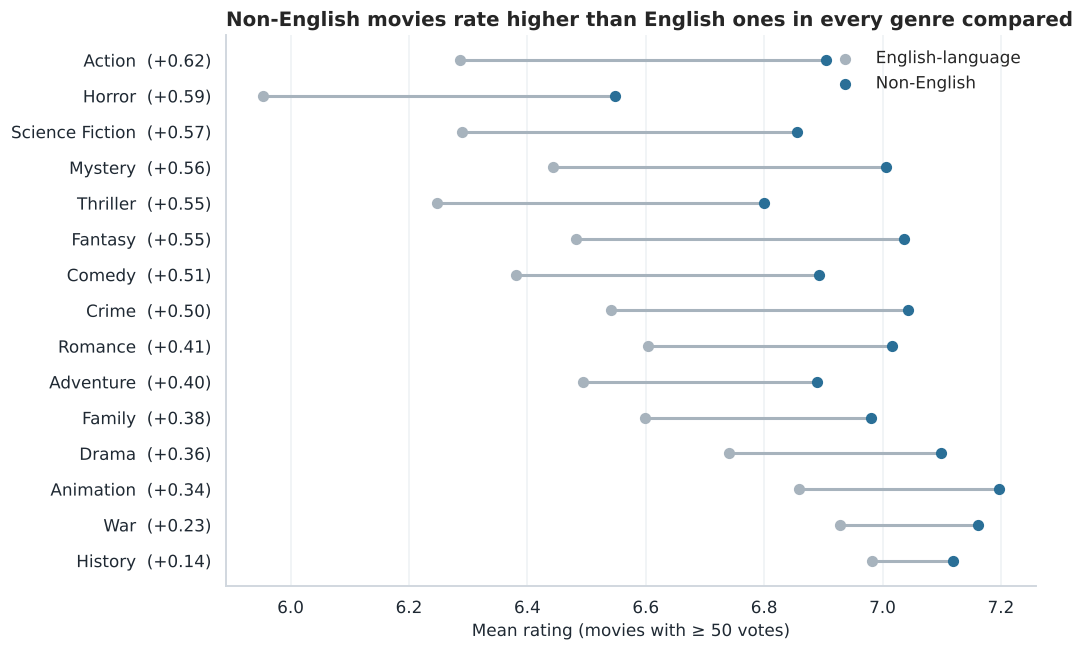

,english_movies,non_english_movies,english_mean,non_english_mean,gap
genre,,,,,
Action,1879,592,6.29,6.91,0.62
Horror,1138,189,5.95,6.55,0.59
Science Fiction,981,192,6.29,6.86,0.57
Mystery,618,115,6.44,7.01,0.56
Thriller,2001,338,6.25,6.80,0.55
Fantasy,884,316,6.48,7.04,0.55
Comedy,2314,470,6.38,6.89,0.51
Crime,966,206,6.54,7.04,0.50
Romance,1028,287,6.60,7.02,0.41


In [22]:
language_gap = da.language_gap_within_genres(movie_genres, min_movies=30)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
plot_df = language_gap.sort_values("gap")
y = np.arange(len(plot_df))
ax.hlines(y, plot_df["english_mean"], plot_df["non_english_mean"], color=MUTED, linewidth=2)
ax.scatter(plot_df["english_mean"], y, color=MUTED, s=40, label="English-language", zorder=3)
ax.scatter(plot_df["non_english_mean"], y, color=PRIMARY, s=40, label="Non-English", zorder=3)
ax.set_yticks(y, [f"{g}  (+{gap:.2f})" for g, gap in zip(plot_df.index.astype(str), plot_df["gap"])])
ax.set(title="Non-English movies rate higher than English ones in every genre compared",
       xlabel="Mean rating (movies with ≥ 50 votes)", ylabel="")
ax.legend(loc="upper right")
ax.grid(axis="y", visible=False)
save(fig, "09_language_gap")
plt.show()

language_gap

**What it shows.** In all 15 genres with at least 30 movies in each group, non-English movies rate higher, by 0.14 (History) to 0.62 points (Action). The gap is therefore not just genre mix.

**Why it matters.** International titles in this catalogue are a pool of well-rated content, relevant to international collections and localisation decisions.

**Caveat: likely selection bias.** TMDB's audience and this "popular" list lean English-language. A non-English film probably only reaches the list if it is unusually acclaimed, while English-language films appear across the quality range. So this shows that *the international titles that reach this list* rate well, not that non-English films are better in general. This is a hypothesis to test with viewing data, not a conclusion.

## 8. Business recommendations

Each recommendation is labelled by the strength of its evidence:
**Observed** = calculated from this dataset; **Hypothesis** = plausible explanation that the dataset cannot confirm; **Needs validation** = would require data this dataset does not contain.

| # | Finding (observed) | Suggested action | Business rationale | Risk / trade-off | KPI to track (needs data not in this set) |
|---|---|---|---|---|---|
| 1 | Popularity is mainly a recency signal (Spearman 0.13 with rating); raw ratings are noisy below 50 votes | Rank "highly rated" surfaces by **vote-weighted rating**; keep popularity for "trending now" only | Each surface then answers the question its label promises | Weighting favours established titles; new releases need time to qualify | Click-through and completion rate per surface |
| 2 | Documentary, History, Music, War and Animation rate highest, but each is ≤ 15% of the catalogue | Use these as **curation** themes (collections, editorial picks) rather than volume acquisition targets | Small but well-received genres can lift perceived catalogue quality | Ratings come from self-selected fans (hypothesis); broad appeal is unproven | Completion rate and rating of curated titles vs catalogue average |
| 3 | 234 "hidden gems": top-10% weighted rating, bottom-half popularity | Pilot a **"hidden gems" / acclaimed-classics row**, tested against the current default row | Under-exposed, well-liked titles add discovery value at no content cost | Low attention may reflect weak demand, not poor exposure (hypothesis) | A/B test: starts and completions from the row vs control |
| 4 | Non-English movies rate 0.14–0.62 points higher within every genre compared | Pilot an **international picks** collection, starting with genres showing the largest gap (Action, Horror, Science Fiction) | Well-rated international content can broaden discovery | Likely selection bias (hypothesis); subtitles and dubbing affect uptake | Engagement with non-English titles; share of users who start one |
| 5 | Genre prevalence and genre rating are unrelated | Report catalogue **mix** and **reception** as separate metrics in planning reviews | Prevents treating "we have a lot of X" as "audiences like X" | Two metrics instead of one in reporting | Adoption in planning dashboards |

None of these findings shows that higher ratings lead to more viewing, revenue or retention. That link needs viewing and subscription data and, ideally, a controlled experiment.

## 9. Limitations and potential biases

- **Not a random sample.** These are movies popular on TMDB around March 2022. Results describe this catalogue, not all films.
- **One snapshot.** Popularity is a point-in-time score that favours recent releases. Re-running on a later snapshot would change Q3, Q4 and the hidden-gems list.
- **Self-selected raters.** TMDB ratings come from users who chose to watch and rate a film; niche genres may be rated mainly by enthusiasts.
- **Survivorship across eras.** Older films in the list are mostly classics, which inflates their ratings relative to recent films.
- **Overlapping genres.** Movies with several genres count in several groups, so genre groups and their confidence intervals are not independent.
- **Thresholds are judgement calls.** The 50-vote cut-off, the weighted-rating prior ($m$ = 555) and the hidden-gem cut-offs (top 10%, bottom half) are assumptions. The weighted ranking was tested with a stricter prior; the others were chosen for interpretability.
- **No commercial outcomes.** The dataset has no viewing, revenue, cost or subscriber data, so no recommendation can be tied to business impact without further data.

## 10. Conclusion and next steps

The popular-movie catalogue is dominated by Drama, Comedy, Action and Thriller, but audience approval is concentrated in smaller genres: Documentary, History, Music, War and Animation. Popularity, engagement and rating behave as separate signals, and raw ratings from few votes are too noisy to rank on. A vote-weighted rating gives a stable, explainable ranking and identifies a pool of well-rated, under-exposed titles.

**Next steps with more data**

1. **Viewing data** (starts, completion, watch time) to test whether ratings and hidden-gem status predict actual engagement.
2. **Several snapshots over time** to separate lasting popularity from release-week spikes.
3. **Availability and licensing data** to check whether hidden gems are under-exposed because they are hard to access.
4. **A/B tests** for the recommended discovery rows, with completion rate as the primary metric.
5. **Text analysis of `Overview`** (for example topic modelling) to find themes that cut across genre tags.

## Appendix: definitions and methodology

| Term | Definition |
|---|---|
| Rating-qualified movie | A movie with at least 50 TMDB votes (8,796 movies) |
| Rating | `Vote_Average`; set to missing when `Vote_Count` = 0 |
| Top quartile | Rating ≥ 7.2, the 75th percentile of rating-qualified movies |
| Genre share | Movies tagged with a genre ÷ all movies (or ÷ movies in the decade, for Q4) |
| 95% confidence interval | Mean ± t(0.975, n−1) × SD / √n, per genre |
| Vote-weighted rating | (v ÷ (v + m)) × R + (m ÷ (v + m)) × C, with m = 555 and C = 6.56 |
| Hidden gem | Weighted rating in the top 10% and popularity at or below the median, among rating-qualified movies |
| Snapshot date | 10 March 2022: the latest release date that has any votes (inferred; the file has no collection date) |
| Spearman correlation | Correlation of ranks; robust to the extreme skew in popularity and vote count |

**Reproducibility.** All cleaning rules and metrics are implemented in `src/data_analysis.py` and covered by `tests/test_data_analysis.py`. The validation cell below re-checks the key invariants every time the notebook runs.

In [23]:
# Validation: these checks fail loudly if a change to the data or the code breaks an invariant.
assert len(movies) == len(raw), "rows were dropped without being logged"
assert movie_genres["movie_id"].nunique() == len(movies)
assert len(movie_genres) == movies["n_genres"].sum()
assert prevalence["movies"].max() <= len(movies)
assert not movies.loc[~movies["has_votes"], "rating"].notna().any(), "a placeholder 0.0 rating leaked into the analysis"
assert (rated["vote_count"] >= da.MIN_VOTES).all()
assert genre_stats["movies"].sum() == movie_genres["rating_qualified"].sum()
assert shortlist_base["weighted"].between(shortlist_base[["rating"]].min().item(), 10).all()
assert hidden_gems["movie_id"].is_unique
print("All validation checks passed.")

All validation checks passed.
